## 1 - Télechargement et traitement du jeu de donnée :

In [5]:
from sklearn.datasets import fetch_openml
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [6]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False)

In [7]:
print(mnist.data.shape)
print(mnist.target.shape)
print(mnist.data.dtype)
print(mnist.target[:10])

(70000, 784)
(70000,)
int64
['5' '0' '4' '1' '9' '2' '1' '3' '1' '4']


Mnist permet donc d'avoir accès aux images et aux étiquettes. Toutefois, il faut faire attention aux formats attendus. Ici les étiquettes sont des chaines de caractères. IL faut donc les convertir en entier. De plus pour ne pas risquer une divergence lors de l'entraînement, on ramène les coefficients des pixels entre 0 et 1, donc on divise par 255. 

In [8]:
X = mnist.data.astype(np.float32) / 255
Y = mnist.target.astype(np.int64)

In [9]:
print(X)
print(Y)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
[5 0 4 ... 4 5 6]


Il faut maintenant séparer le jeu de données en jeu d'entraînement et jeu de test.

In [10]:
X_train, Y_train = X[:60000], Y[:60000]
X_test, Y_test = X[60000:], Y[60000:]

print(X_train.shape, X_test.shape)

(60000, 784) (10000, 784)


Il ne faut jamais que le réseau voit le jeu de test pendant sont entrînement pour vérifier qu'il apprend bien une généralisation et pas des cas spécifiques.

## 2 - Algorithme avec PyTorch : 

Il faut convertir les tableaux Numpy en tenseur Torch. Il y a deux différences. Premièrement, un tenseur peut-être déplacé sur une carte graphique et deuxièmement, un tenseur peut mémoriser l'historique des opérations qu'on lui applique. 

In [11]:
X_train = torch.tensor(X_train)
X_test = torch.tensor(X_test)
Y_train = torch.tensor(Y_train)
Y_test = torch.tensor(Y_test)

print(type(X_train))
print(X_train.shape, X_train.dtype)
print(Y_train.shape, Y_train.dtype)

<class 'torch.Tensor'>
torch.Size([60000, 784]) torch.float32
torch.Size([60000]) torch.int64


Il faut maintenant contruire le modèle. Ce dernier est constitué de deux couches de perceptron avec une étape ReLU au milieu 784 → 256 → 10. Cette étape consiste à prendre 0 si l'une des sorties de la première couche de perceptron était négative. Cela permet d'introduire une non linéarité qui permet de modéliser les frontières correctement. On indique également la fonction de perte, qui permettra justement de calculer à l'issue de chaque batch une moyenne de la perte afin de corriger. 

In [12]:
model_init = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
)

loss_fn_init = nn.CrossEntropyLoss()

On peut alors se demander ce que fait nn.Linear. En réalité, c'est juste un raccourci de l'opération Wx + b. Linear permet de créer et stocker W et b et nn.Linear(x) renvoie alors Wx + b.

In [13]:
couche = nn.Linear(3, 2)
x = torch.tensor([2.4, 3.2, 0.3])

print(couche(x))
print(couche.weight @ x + couche.bias)

tensor([1.0784, 1.3331], grad_fn=<ViewBackward0>)
tensor([1.0784, 1.3331], grad_fn=<AddBackward0>)


On peut inspecter alors le modèle que l'on a crée. 

In [14]:
test_model = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
)

for nom, p in test_model.named_parameters():
    print(nom, p.shape, p.numel())

0.weight torch.Size([256, 784]) 200704
0.bias torch.Size([256]) 256
2.weight torch.Size([10, 256]) 2560
2.bias torch.Size([10]) 10


On fait maintenant passer une vrai image du jeu de test dans le modèle pour voir comment il réagit. C'est important de faire ça avant de lancer un entraînement. 

In [15]:
scores = test_model(X_train[0])
print(scores)
print(scores.argmax(), Y_train[0])

tensor([-0.0225, -0.0470, -0.0613,  0.1068, -0.0514, -0.1286,  0.1417, -0.0895,
        -0.0509,  0.0367], grad_fn=<ViewBackward0>)
tensor(6) tensor(5)


Scores est un tensor torch qui est de dimension 10. Il renvoie la réponse de la deuxième couche de perceptrons. scores.argmax permet d'avoir accès à la place de la plus haute valeur du tensor. Cela correspond donc à la prédiction du modèle. Y_train[0] renvoie lui la véritable réponse qu'il fallait donner. Il reste alors à indiquer au modèle comment modifier ses poids. Avant cela, on peut juste vérifier que avant de lancer la phase d'entraînement, notre modèle à bien été sélectionné aléatoirement et que la probabilité qu'il donne la bonne réponse en l'état est proche de 0.1. On teste sur les 10000 images de test. 

torch.Size([10000, 10])
torch.Size([10000])


<BarContainer object of 10 artists>

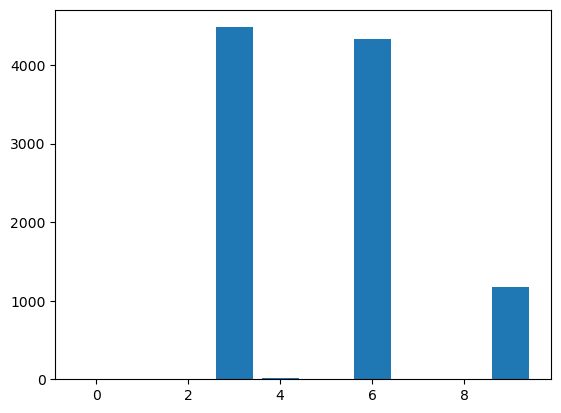

In [16]:
scores_test = test_model(X_test)
print(scores_test.shape)

pred = scores_test.argmax(dim=1)
print(pred.shape)

les_k = np.array([k for k in range(0, 10)])
"""
Cette partie peut être remplacée par une seule ligne.
tab = []
for nb in les_k:
    compteur = 0
    for element in pred:
        if element == nb:
            compteur += 1
    print(compteur)
    tab.append(compteur)
tab = np.array(tab)
print(tab)
"""
tab = torch.bincount(pred, minlength = 10)
plt.bar(les_k, tab)


     

On observe une répartition très inégale. Cela signifie que les poids ont tendance à préférer donner certains chiffres. Ici c'est le 3. C'est cohérent à ce stade : il aurait été surprenant au contraire de voir toutes les barres à 10000, ce que doit fiare notre algorithme à la fin, sous réserve que il y ait équirépartition des chiffres dans le jeu de test. On calcule maintenant la probabilité de trouver un certains nombres. 

In [17]:
scores_test = test_model(X_test)
print(scores_test.shape)

pred = scores_test.argmax(dim=1)
print(pred.shape)

les_k = np.array([k for k in range(0, 10)])

diff = pred - Y_test
compteur = 0

for element in diff:
    if element == 0:
        compteur += 1

print(compteur/10000)

torch.Size([10000, 10])
torch.Size([10000])
0.0636


On obtient une probabilité de bonne réponse de l'ordre de 0.1, ce qui est cohérent et confirme le caractère aléatoire du modèle à ce stade. On commence alors la phase d'entraînement en définissant l'optimiseur, c'est le gestionnaire des poids. C'est lui qui les modifiera selon le gradient. On fixe pour le moment la taille d'un pas à 0.1. Pour que l'optimiseur identifie correctement le modèle, il faut que celui ci soit défini dans la même cellule. C'est l'objet de celle ci-dessous.

In [18]:
model = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(model.parameters(), lr = 0.1)
print(optimizer)

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


On voit ici tous les paramètres de l'optimiseur. On peut les modifier selon le pb que l'on veut résoudre j'imagine. Dans la cellule suivante, je crée le batch (ie : les échantillons qui permettront de calculer un pas)

In [19]:
X_batch = X_train[:64]
Y_batch = Y_train[:64]
print(X_batch.shape, Y_batch.shape)

torch.Size([64, 784]) torch.Size([64])


On fait alors passer le batch dans le réseau. 

In [20]:
scores = model(X_batch)
print(scores.shape)

torch.Size([64, 10])


In [21]:
loss = loss_fn(scores, Y_batch)
print("avant :", loss.item())

optimizer.zero_grad()
loss.backward()
optimizer.step()

print("après :", loss_fn(model(X_batch), Y_batch).item())

avant : 2.3125805854797363
après : 2.27070951461792


Il est maintenant de faire la boucle d'entraînement. Le principe est simple, il faut répéter les opérations suviantes le nombre de batch qu'il y a : changer de batch et faire la descente de gradient. Les batchs doivent être sélectionnés aléatoirement.

In [22]:
## On réorganise les indices aléatoirement pour avoir des batchs aléatoires :
perm = torch.randperm(60000)
loss_values = []
for debut in range(0, 60000, 64):
    current_batch = perm[debut:debut+64]
    X_batch = X_train[current_batch]
    Y_batch = Y_train[current_batch]

    scores = model(X_batch)

    loss = loss_fn(scores, Y_batch)
    loss_values.append(loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

loss_values = np.array(loss_values)

    



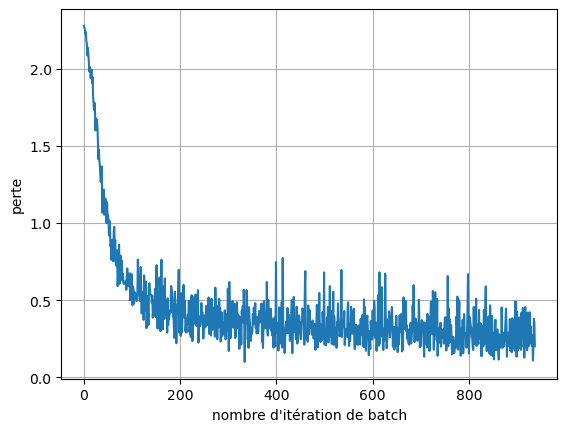

In [23]:
plt.plot(loss_values)
plt.ylabel("perte")
plt.xlabel("nombre d'itération de batch")
plt.grid()

On passe maintenant à l'évaluation de notre modèle sur le jeu de donnée de test. On peut enlever le calcul de gradient de torch qui permet de gagner en rapidité de calcul.

In [24]:
with torch.no_grad():
    scores_test = model(X_test)

pred = scores_test.argmax(dim = 1)

good = (pred == Y_test)

nb_good = good.sum().item()

precision = nb_good/len(Y_test)

print(precision)

0.9246


La précision est cohérente, avec plus de 90% de bonnes réponses contre seulement 10% avant l'entraînement. Cependant, on pourrait peut-être progresser encore ou du moins préciser en essayant d'entraînet le modèle sur plusieurs tailles de batch. Cela permettra de connaître l'influence de ce paramêtre sur l'apprentissage et la précision du modèle. 

## 3 - Etude de l'influence de la taille des batchs

Pour cette partie, l'enjeu est de créer une fonction qui refait l'apprentissage de la partie précédente pour une taille de batch quelconque.

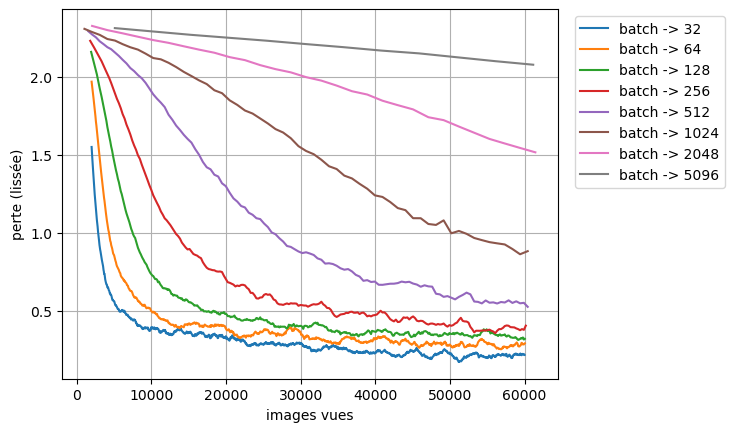

In [25]:
def test_batch (taille_batch):

    model = nn.Sequential(
        nn.Linear(784, 256),
        nn.ReLU(),
        nn.Linear(256, 10),
    )

    loss_fn = nn.CrossEntropyLoss()
    
    optimizer = torch.optim.SGD(model.parameters(), lr = 0.1)

    X = mnist.data.astype(np.float32)/255
    Y = mnist.target.astype(np.int64)

    X_train, Y_train = X[:60000], Y[:60000]
    X_test, Y_test = X[60000:], Y[60000:]

    X_train = torch.tensor(X_train)
    Y_train = torch.tensor(Y_train)
    X_test = torch.tensor(X_test)
    Y_test = torch.tensor(Y_test)

    loss_values = []

    perm = torch.randperm(60000)
    
    for debut in range(0, 60000, taille_batch):
        indices = perm[debut:debut + taille_batch]


        X_batch = X_train[indices]
        Y_batch = Y_train[indices]

        scores = model(X_batch)

        loss = loss_fn(scores, Y_batch)

        loss_values.append(loss.item())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    return model, loss_values 

lg_batch = [32, 64, 128, 256, 512, 1024, 2048, 5096]

losses = [test_batch(element)[1] for element in lg_batch]

for i in range(len(lg_batch)):
    l = np.array(losses[i])

    # fenêtre de lissage : environ 1/30 de la longueur de la courbe, au moins 1
    w = max(1, len(l) // 30)
    lisse = np.convolve(l, np.ones(w) / w, mode="valid")

    # abscisse : nombre d'images vues après chaque pas
    images_vues = (np.arange(len(l)) + 1) * lg_batch[i]

    plt.plot(images_vues[w-1:], lisse, label=f"batch -> {lg_batch[i]}")

plt.xlabel("images vues")
plt.ylabel("perte (lissée)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid()
plt.show()

In [26]:
print(losses)


[[2.321427345275879, 2.3066205978393555, 2.2745189666748047, 2.2618532180786133, 2.2222156524658203, 2.201327085494995, 2.2004048824310303, 2.2183823585510254, 2.163581371307373, 2.1127865314483643, 2.088054895401001, 2.108973741531372, 2.0678560733795166, 2.0621213912963867, 1.9560290575027466, 1.9727990627288818, 1.9741847515106201, 1.9359699487686157, 1.8864927291870117, 1.9323064088821411, 1.7221266031265259, 1.8384052515029907, 1.671826958656311, 1.7163307666778564, 1.7139943838119507, 1.7508695125579834, 1.71939218044281, 1.652782917022705, 1.5476502180099487, 1.6169657707214355, 1.406291127204895, 1.5300532579421997, 1.3978980779647827, 1.4637054204940796, 1.3482059240341187, 1.2813494205474854, 1.3562983274459839, 1.210520625114441, 1.3019815683364868, 1.1268073320388794, 1.058076024055481, 1.2354742288589478, 1.1691133975982666, 1.072364091873169, 1.2691055536270142, 0.9171460270881653, 1.1004186868667603, 1.0658425092697144, 1.3386098146438599, 1.258278489112854, 0.9399917721

Ce graphique permet ainsi de voir que avec 60000 images, la confiance du modèle est d'autant plus grande que la taille des batchs utilisés est petite. Cela peut s'expliquer assez intuitivement : avec une taille de batch de 5096, l'algorithme n'a effectué qu'une quinzaine de pas, ce qui ne lui permet evidemment pas d'être aussi performant et confiant qu'un algorithe ayant effectué presque 2000 pas. 

## 4 - Étude du voisinage des solutions :

Comme dans la partie 1, l'enjeu est maintenant de voir si l'algorithme est capable de trouver des solutions isolés, où bien s'il continue de trouver des solutions dans des régions denses. Pour cela, il faut modifier un peu la procédure par rapport à l'étude précédente. En effet, dans la partie 3, nous avons quantifié en première approche l'efficacité du modèle pour différentes tailles de batch. Nous avons alors conclu que la perte atteignait un minimum d'autant plus vite que la taille des batchs était faible. Or dans notre cas, une solution correspond au cas où le minimum de la perte est atteint. Ainsi, toutes les tailles de batch ne seront pas visionnées le même nombre de fois par le modèle. L'enjeu est clair : permettre au modèle d'accéder aux solutions quelque soit la taille du batch. De plus, pour vérifier que les algorithmes ont atteint une perte qui correspond bien à une solution et pas seulement à une solution sur un batch "facile", on considère et on compare perte_globale, qui recalcule perte sur l'ensemble des données du jeu d'entraînement.

In [27]:
from tqdm.notebook import tqdm

X = mnist.data.astype(np.float32) / 255
Y = mnist.target.astype(np.int64)

n_train = 10000                      

X_train = torch.tensor(X[:n_train])
Y_train = torch.tensor(Y[:n_train])
X_test  = torch.tensor(X[60000:])
Y_test  = torch.tensor(Y[60000:])


def test_batch_2(taille_batch, n_epoque_max, seuil):

    model = nn.Sequential(
        nn.Linear(784, 256),
        nn.ReLU(),
        nn.Linear(256, 10),
    )
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr = 0.1)

    for n_epoque in tqdm(range(1, n_epoque_max + 1), desc=f"batch {taille_batch}", leave=False):

        perm = torch.randperm(n_train)

        for debut in range(0, n_train, taille_batch):
            indices = perm[debut:debut + taille_batch]

            X_batch = X_train[indices]
            Y_batch = Y_train[indices]

            scores = model(X_batch)
            loss = loss_fn(scores, Y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        
        with torch.no_grad():
            scores = model(X_train)
            perte_globale = loss_fn(scores, Y_train).item()

        if perte_globale < seuil:
            break

    return model, perte_globale, n_epoque



n_epoque_max = 1000
seuil = 0.01
les_lg_batch = [32, 128, 512, 1024]

resultats = [test_batch_2(element, n_epoque_max, seuil) for element in tqdm(les_lg_batch)]

  0%|          | 0/4 [00:00<?, ?it/s]

batch 32:   0%|          | 0/1000 [00:00<?, ?it/s]

batch 128:   0%|          | 0/1000 [00:00<?, ?it/s]

batch 512:   0%|          | 0/1000 [00:00<?, ?it/s]

batch 1024:   0%|          | 0/1000 [00:00<?, ?it/s]

In [28]:
les_modeles = [r[0] for r in resultats]
les_pertes  = [r[1] for r in resultats]
les_epoques = [r[2] for r in resultats]

print(les_pertes, les_epoques)

[0.009826223365962505, 0.009851218201220036, 0.009949939325451851, 0.009991645812988281] [29, 119, 486, 988]


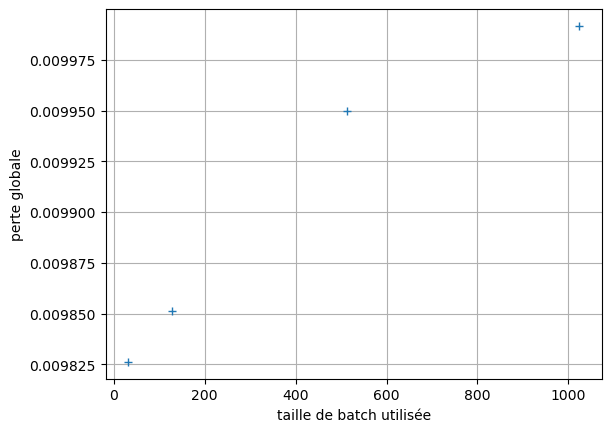

In [29]:
n_epoque_max = 1000

les_lg_batch = [32, 128, 512, 1024]

plt.plot(les_lg_batch, les_pertes, '+')
plt.xlabel("taille de batch utilisée")
plt.ylabel("perte globale")
plt.grid()

plt.show()

On voit que pour toutes les tailles de batch, la perte globale passe en dessous du seuil de 0.1 fixé. C'est cohérent et nous allons donc pouvoir comparer l'impact des différentes tailles de batch sur le voisinage des solutions trouvées. Toutefois, on constate que pour les faibles tailles de batch (32 et 64), la perte est plus basse que les autres. Nous en tiendrons compte dans les analyses futures. Le but est maintenant d'évaluer la précision de nos modèles sur le jeu de donées de test. 

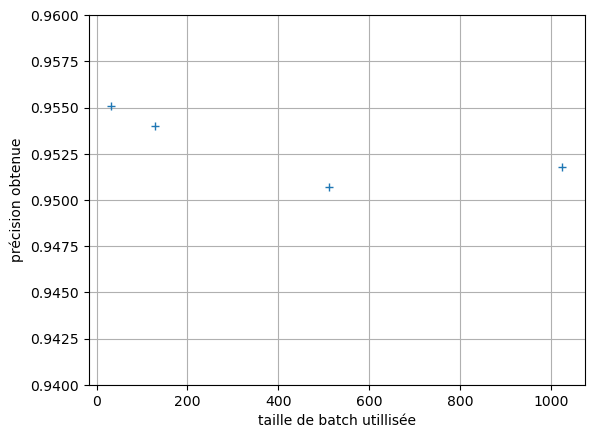

In [30]:
les_precisions = []
for modele in les_modeles:
    with torch.no_grad():
        scores = modele(X_test)

    pred = scores.argmax(dim = 1)

    good = (pred == Y_test)

    nb_good = good.sum().item()

    precision = nb_good/len(Y_test)

    les_precisions.append(precision)

plt.plot(les_lg_batch, les_precisions, '+')
plt.grid()
plt.xlabel('taille de batch utillisée')
plt.ylabel('précision obtenue')

plt.ylim(0.94, 0.96)
plt.show()

On constate qu'il y a une petite tendance décroissante de la précision. Cependant celle-ci ne peut être clairement attribuée à la variation de la taille du batch. En effet, il y avait une différence de perte à la fin des itérations qui peut être à l'origine des ces écarts. De plus, il peut également y avoir du bruit. La descente de gradient a été seulement effectuée une seule fois pour chaque taille de batch, ce qui ne permet pas de tirer de conclusion certaine. Pour réussir à trancher, nous proposons maintenant de faire ce travail sur un jeu de données plus "dures" à classer : des vêtements et de le faire sur une plus grande plage de batch tout en moyennant.

In [31]:
## On importe le jeu de données : 
mnist = fetch_openml("Fashion-MNIST", as_frame = False)

## On récupère les données :
X = mnist.data.astype(np.float32)/255
Y = mnist.target.astype(np.int64)

In [ ]:
## On sépare le jeu de données : 
X_train, Y_train = X[:60000], Y[:60000]
X_test, Y_test = X[60000:], Y[60000:]

print(Y)
## On convertit en tenseur PyTorch : 
X_train = torch.tensor(X_train)
Y_train = torch.tensor(Y_train)
X_test = torch.tensor(X_test)
Y_test = torch.tensor(Y_test)

def test_batch_3(taille_batch, n_epoque_max, seuil):

    ## Définition du modèle (10 vêtements différents à classer) :
    model = nn.Sequential(
        nn.Linear(784, 256), 
        nn.ReLU(), 
        nn.Linear(256, 10),
    )

    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr = 0.1)

    for n_epoque in tqdm(range(1, n_epoque_max + 1), desc=f"batch {taille_batch}", leave=False):
        perm = torch.randperm(60000)

        for debut in range(0, 60000, taille_batch):
            indices = perm[debut:debut + taille_batch]

            X_batch = X_train[indices]
            Y_batch = Y_train[indices]

            scores = model(X_batch)
            loss = loss_fn(scores, Y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            scores = model(X_train)
            perte_globale = loss_fn(scores, Y_train).item()

        if perte_globale < seuil:
            break

    return model, perte_globale, n_epoque


n_epoque_max = 1000
seuil = 0.01
les_lg_batch = [32, 128, 512, 1024]


resultats = [test_batch_3(element, n_epoque_max, seuil) for element in tqdm(les_lg_batch)]

[9 0 0 ... 8 1 5]


  0%|          | 0/4 [00:00<?, ?it/s]

batch 32:   0%|          | 0/1000 [00:00<?, ?it/s]

batch 128:   0%|          | 0/1000 [00:00<?, ?it/s]

batch 512:   0%|          | 0/1000 [00:00<?, ?it/s]

In [ ]:
les_modeles = [r[0] for r in resultats]
les_pertes  = [r[1] for r in resultats]
les_epoques = [r[2] for r in resultats]

In [ ]:
les_precisions = []
for modele in les_modeles:
    with torch.no_grad():
        scores = modele(X_test)

    pred = scores.argmax(dim = 1)

    good = (pred == Y_test)

    nb_good = good.sum().item()

    precision = nb_good/len(Y_test)

    les_precisions.append(precision)

plt.plot(les_lg_batch, les_precisions, '+')
plt.grid()
plt.xlabel('taille de batch utillisée')
plt.ylabel('précision obtenue')

plt.ylim(0.85, 0.95)

plt.show()

Finalement, nous voyons la encore qu'il n'y pas d'influence nette de la taille du batch sur la précision du modèle à perte égale. En effet, pour les grosses tailles de batch, l'algorithme a été entrainé plus longtemps. Ce paramètre permet ainsi d'atteindre une perte égale pour que l'étude se porte uniquement sur l'influence de la taille du batch. Nous pouvons donc en conclure que la précision ne semble pas dépendre de la taille du batch. La seule influence est dans la durée d'apprentissage : beaucoup plus longue pour des tailles de batch élevées. Nous revenons donc à une étude du voisinage pour déterminer le type de solutions trouvées par notre algorithme. Cette fois ci, une fois la solution trouvée, nous faisons varier chacun des poids et mesurons la perte pour voir si le voisinage d'une solution trouvée par l'algoritme est toujours une solution. 

In [ ]:
def perte_perturbee(model, sigma):
    loss_fn = nn.CrossEntropyLoss()

    with torch.no_grad():
        ## Pour chaque modèle, on stocke les poids d'origine pour les remettre après : 
        sauvegarde = [p.clone() for p in model.parameters()]

        ## On ajoute pour chaque poids des coeffs différents aléatoires mais en tenant compte de la valeur des poids pour que l'influence soit la même : 
        for p in model.parameters():
            p.add_(sigma * p.abs().mean() * torch.randn_like(p))
    
        scores = model(X_train)
        perte_globale = loss_fn(scores, Y_train).item()

        for p, s in zip(model.parameters(), sauvegarde):    
            p.copy_(s)

    return perte_globale

les_sigma = [0.05, 0.1, 0.2, 0.5, 1]


## A cause du bruit induit par sigma, on moyenne sur 5 itérations :
def calcul_perte_moy(sigma):  
    les_pertes_moy = []
    for m in les_modeles:
        perte_depart = perte_perturbee(m, 0)
        perte = 0
        for k in range(5):
            perte += perte_perturbee(m, sigma)
        les_pertes_moy.append(perte/5 - perte_depart)
    return les_pertes_moy

les_sigma = [0.005, 0.01, 0.02, 0.05, 0.1]
les_hausses = [calcul_perte_moy(sigma) for sigma in les_sigma]


for j in range(len(les_modeles)):
    hausses_modele = [les_hausses[i][j] for i in range(len(les_sigma))]
    plt.plot(les_sigma, hausses_modele, 'o-', label=f"batch {les_lg_batch[j]}")

plt.xlabel("amplitude de la perturbation sigma")
plt.ylabel("hausse de la perte d'entraînement")
plt.legend()
plt.grid()
plt.show()  

Pour comparer les effets de la perturbation de manière cohérente entre les différentes tailles de batch, on prend une perturbation proportionnelle aux poids. Les résultats sont les suivants : on constate que plus la taille du batch est élevée, plus la perturbation augmente la perte. De plus, de manière logique est commune à toutes les tailles de batch, celle-ci augmente avec l'amplitude de la perturbation. Cela signifie que les algorithmes avec des tailles de batch élevées ont tendance à trouver des solutions plus "étroites" que les algorithmes avec des tailles de batchs plus petites, qui ont eux tendance à trouver des solutions dans des régions plus "plates".  Toutefois, par manque de temps, je n'ai pas eu le temps de faire plusieurs entraînements et modèles par taille de batch. Ce résultat est donc un résultat sur un entraînement. Cela constitue une limite majeure. 